In [33]:
import torch
import matplotlib.pyplot as plt

from ngo.numericalanalysis.basisfunctions import *
from ngo.numericalanalysis.linalg import *
from ngo.trainingdata.GRF import *

In [34]:
torch.cuda.empty_cache()
N_samples = 100
lambdas=(0.5,)
b_min = -1
b_max = 1
b = torch.rand(N_samples)*(b_max - b_min) + b_min
c_min = 0
c_max = 1
c = torch.rand(N_samples)*(c_max - c_min) + c_min
grf = GRF(N_samples=N_samples, lambdas=lambdas, b=b, c=c, device='cuda', dtype=torch.float64, n=None)

In [4]:
grf.f_m.shape

torch.Size([100, 3])

In [7]:
grf.lambdas.shape

torch.Size([1])

In [8]:
basis_t = GaussianRBFBasis(lambdas=grf.lambdas[0], mus=grf.mus[0])

In [9]:
t = torch.linspace(0,1,1000, device='cuda', dtype=torch.float64)
basis_t.forward(t).shape

torch.Size([1, 3, 1000])

In [10]:
grf.f_m.shape

torch.Size([100, 3])

In [11]:
grf.f.shape

torch.Size([100, 3])

(-3.0, 3.0)

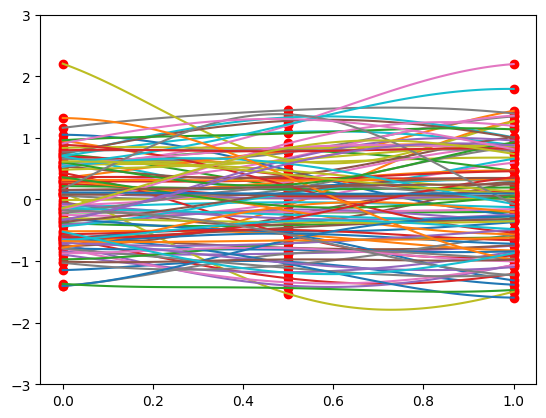

In [12]:
sample = 1
t = torch.linspace(0,1,100, device='cuda', dtype=torch.float64)
y = torch.einsum('Nn,Nnx->Nx', grf.f_m, basis_t.forward(t))
for sample in range(100):
    plt.plot(t.cpu(), y[sample].cpu())
    plt.scatter(grf.mus[0].cpu(), grf.f[sample].cpu(), color='red')
plt.ylim(-3,3)

In [14]:
torch.cuda.empty_cache()
lambdas = (0.1,0.1)
grf = GRF(N_samples=N_samples, lambdas=lambdas, b=b, c=c, n=None, device='cuda', dtype=torch.float64)

/home/joostprins/git/ngo-pde-gk/src/ngo/trainingdata/GRF.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.b = torch.tensor(b, device=self.device, dtype=dtype)
/home/joostprins/git/ngo-pde-gk/src/ngo/trainingdata/GRF.py:60: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.c = torch.tensor(c, device=self.device, dtype=dtype)


In [15]:
grf.f_m.shape

torch.Size([100, 11, 11])

In [17]:
grf.lambdas.shape

torch.Size([2])

In [18]:
basis_t = GaussianRBFBasis(lambdas=grf.lambdas[0], mus=grf.mus[0])
basis_x = GaussianRBFBasis(lambdas=grf.lambdas[1], mus=grf.mus[1])

basis = TensorProductBasis((basis_t, basis_x))

In [19]:
t = torch.linspace(0,1,1000, device='cuda', dtype=torch.float64)
x = torch.linspace(0,1,1000, device='cuda', dtype=torch.float64)
X = (t,x)

In [20]:
basis.forward(grf.f_m, X).shape

torch.Size([100, 1000, 1000])

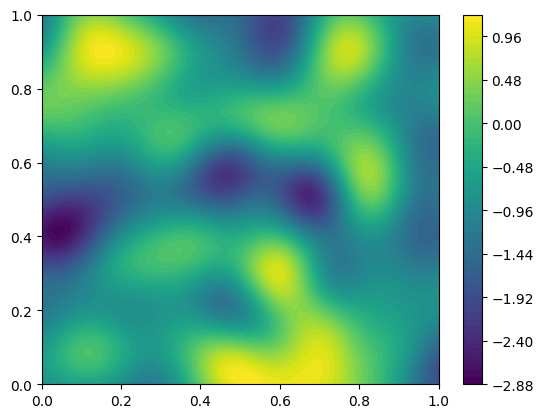

In [21]:
grid = torch.meshgrid(t.cpu(), x.cpu(), indexing='ij')
mus_grid = torch.meshgrid(grf.mus[0], grf.mus[1], indexing='ij')
plt.contourf(grid[1], grid[0], basis.forward(grf.f_m, X).cpu()[0], levels=50)
plt.colorbar()

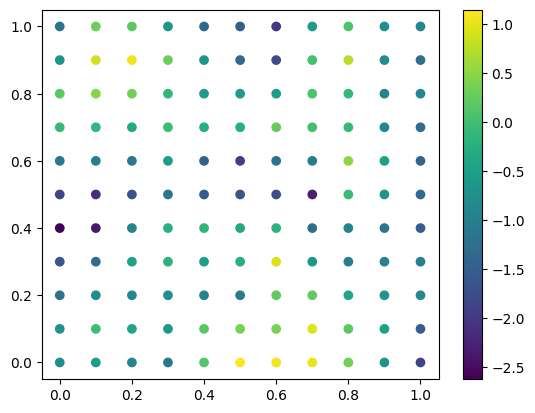

In [22]:
grid = torch.meshgrid(t.cpu(), x.cpu(), indexing='ij')
mus_grid = torch.meshgrid(grf.mus[0], grf.mus[1], indexing='ij')
plt.scatter(mus_grid[1].cpu(), mus_grid[0].cpu(), c=grf.f[0].cpu())
plt.colorbar()

In [24]:
l_min = 0.1
l_max = 1
lambdas = torch.rand(N_samples,1, dtype=torch.float64, device='cuda')*(l_max - l_min) + l_min

n = (9,)
f_set = torch.zeros((N_samples, *n), device='cuda', dtype=torch.float64)
f_m_set = torch.zeros((N_samples, *n), device='cuda', dtype=torch.float64)

for i in range(N_samples):
    grf = GRF(N_samples=1, lambdas=lambdas[i], b=b[i], c=c[i], device='cuda', dtype=torch.float64, n=n)
    f_set[i] = grf.f
    f_m_set[i] = grf.f_m

/home/joostprins/git/ngo-pde-gk/src/ngo/trainingdata/GRF.py:52: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.lambdas = torch.tensor(lambdas, device=self.device, dtype=dtype)
/home/joostprins/git/ngo-pde-gk/src/ngo/trainingdata/GRF.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.b = torch.tensor(b, device=self.device, dtype=dtype)
/home/joostprins/git/ngo-pde-gk/src/ngo/trainingdata/GRF.py:60: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.c = torch.tensor(c, device=self.device, dtype=dtype)


In [25]:
basis_t = GaussianRBFBasis(lambdas=lambdas[:,0], mus=grf.mus[0])

(-2.0, 2.0)

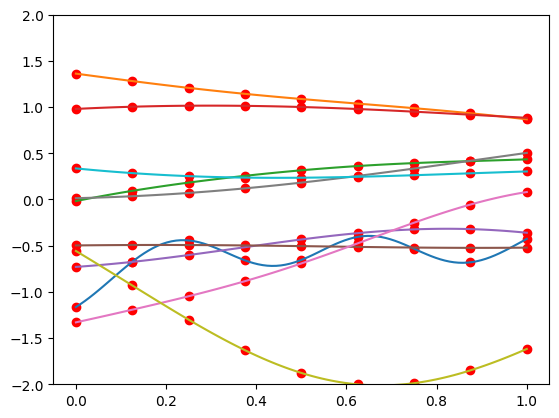

In [26]:
t = torch.linspace(0,1,100, device='cuda', dtype=torch.float64)
y = torch.einsum('Nn,Nnx->Nx', f_m_set, basis_t.forward(t))
for sample in range(10):
    plt.plot(t.cpu(), y[sample].cpu())
    plt.scatter(grf.mus[0].cpu(), f_set[sample].cpu(), color='red')
plt.ylim(-2,2)

In [27]:
l_min = 0.1
l_max = 1
lambdas = torch.rand(N_samples,2, dtype=torch.float64, device='cuda')*(l_max - l_min) + l_min
n = (9,9)
f_set = torch.zeros((N_samples, *n), device='cuda', dtype=torch.float64)
f_m_set = torch.zeros((N_samples, *n), device='cuda', dtype=torch.float64)

for i in range(N_samples):
    grf = GRF(N_samples=1, lambdas=lambdas[i], b=b[i], c=c[i], device='cuda', dtype=torch.float64, n=n)
    f_set[i] = grf.f
    f_m_set[i] = grf.f_m

/home/joostprins/git/ngo-pde-gk/src/ngo/trainingdata/GRF.py:52: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.lambdas = torch.tensor(lambdas, device=self.device, dtype=dtype)
/home/joostprins/git/ngo-pde-gk/src/ngo/trainingdata/GRF.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.b = torch.tensor(b, device=self.device, dtype=dtype)
/home/joostprins/git/ngo-pde-gk/src/ngo/trainingdata/GRF.py:60: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.c = torch.tensor(c, device=self.device, dtype=dtype)


In [28]:
basis_t = GaussianRBFBasis(lambdas=lambdas[:,0], mus=grf.mus[0])
basis_x = GaussianRBFBasis(lambdas=lambdas[:,1], mus=grf.mus[1])

basis = TensorProductBasis((basis_t, basis_x))

In [29]:
t = torch.linspace(0,1,100, device='cuda', dtype=torch.float64)
x = torch.linspace(0,1,100, device='cuda', dtype=torch.float64)
X = (t,x)

basis.forward(f_m_set, X).shape

torch.Size([100, 100, 100])

In [30]:
sample = 0

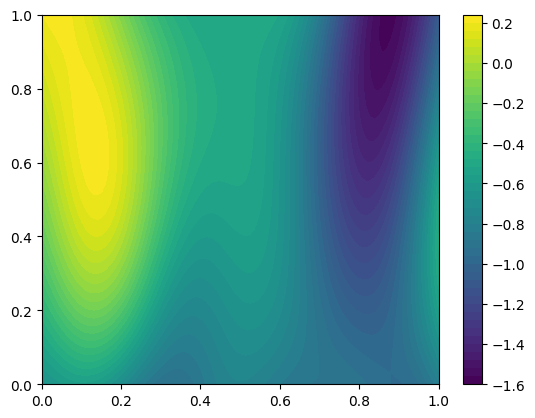

In [31]:
grid = torch.meshgrid(t.cpu(), x.cpu(), indexing='ij')
mus_grid = torch.meshgrid(grf.mus[0], grf.mus[1], indexing='ij')
plt.contourf(grid[1], grid[0], basis.forward(f_m_set, X).cpu()[sample], levels=50)
plt.colorbar()

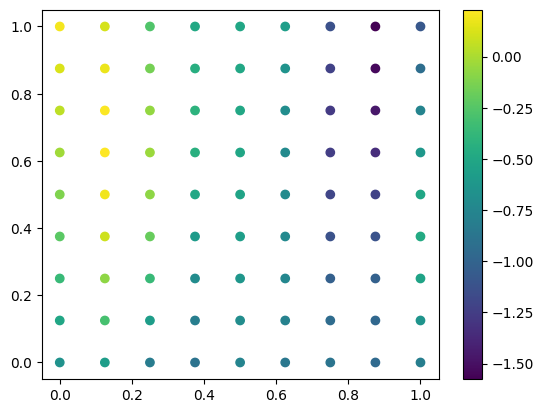

In [32]:
grid = torch.meshgrid(t.cpu(), x.cpu(), indexing='ij')
mus_grid = torch.meshgrid(grf.mus[0], grf.mus[1], indexing='ij')
plt.scatter(mus_grid[1].cpu(), mus_grid[0].cpu(), c=f_set[sample].cpu())
plt.colorbar()